# Bank Marketing — Exploratory Data Analysis
## Assignment 1: Statistical Learning and Data Analysis

This notebook continues the original program using the supplied `bank.csv` dataset. It answers all five analysis sections in the assignment image, adds **SelectKBest**, and explains the original and new code in Markdown.

**How to run:** keep `bank.csv` in the same folder as this notebook and choose **Restart Kernel and Run All**. Required packages: `pandas`, `numpy`, `seaborn`, `matplotlib`, `scipy`, `scikit-learn` and a Jupyter Python kernel. Saved outputs are included so the results can also be read without running the code.

**Reading order**

1. Part A explains and preserves the original work.
2. Part B completes the questions on loading, cleaning and univariate analysis.
3. Part C continues the bivariate analysis with SelectKBest.
4. Part D completes PCA and clustering.
5. Part E summarises the findings and limitations.

**What was changed:** the original code order and variable names are retained. Only `plt.Figure` was corrected to `plt.figure`, misleading plot labels/titles were corrected, and a repeated assignment was removed. The incorrect correlation and outlier explanations were rewritten. New analysis is added after the original work.

**Scope:** this is an EDA assignment, so it does not require training a prediction model. The image also asks for an HTML/PDF version and a short presentation; this requested deliverable is the `.ipynb` notebook. Those additional submission formats are separate deliverables.

# Part A — Original program, explained

## Loading and exploring the data
`pandas` reads and organises the table. `seaborn` and `matplotlib.pyplot` draw plots. `%matplotlib inline` displays figures inside Jupyter. `sep=';'` is needed because this CSV separates values with semicolons.

`head(5)` and `tail(5)` show the first and last five rows. `unique()` lists the different values in a column. `shape[0]` gives the number of rows; `shape[1]` would give the number of columns.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

### Loading Data Set and viewing it

In [2]:
df=pd.read_csv('bank.csv', sep=';')
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df['month'].unique()

array(['may', 'jun', 'jul', 'aug', 'oct', 'nov', 'dec', 'jan', 'feb',
       'mar', 'apr', 'sep'], dtype=object)

In [4]:
df['job'].unique()

array(['management', 'technician', 'entrepreneur', 'blue-collar',
       'unknown', 'retired', 'admin.', 'services', 'self-employed',
       'unemployed', 'housemaid', 'student'], dtype=object)

In [5]:
df.tail(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [6]:
df.shape[0]

45211

#### Result
The original dataset contains **45,211 observations** before age filtering.

`mean()` calculates an average. Here the original program looks at average balance and average call duration; these variables have different units and meanings.

In [7]:
int(df['balance'].mean())

1362

In [8]:
int(df['duration'].mean())

258

### Checking missing values and duplicates
`isna().sum()` counts actual missing values in every column. `duplicated().sum()` counts fully repeated rows. The text `unknown` is a category, so `isna()` does not count it; Part B checks it separately.

In [9]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

There are **no actual NaN values**. No numerical imputation is needed. This does not mean every field is known: some categorical columns contain `unknown`.

In [10]:
df.duplicated().sum()

np.int64(0)

There are **0 fully duplicated rows**, so no duplicate rows need to be removed.

### Numerical summary
`describe()` reports count, mean, standard deviation, minimum, quartiles and maximum for numeric columns. It does not include mode by default; Part B adds it.

In [11]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


The summary helps identify typical values and unusually large observations. The earlier `int(mean())` cells truncate the mean to an integer; Part B keeps decimal precision. A large value should be investigated before it is treated as an error.

### Comparing the maximum age and maximum previous-contact gap
This preserves the original bar chart. Age and `pdays` have different units, so their bar heights do not establish a relationship. Separate distribution plots later are more informative.

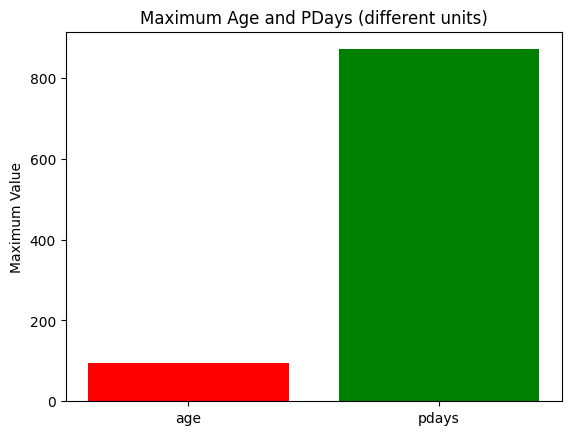

In [12]:
max_age=df['age'].max()
max_pdays=df['pdays'].max()

plt.bar(['age','pdays'],[max_age,max_pdays],color=['red','green'])
plt.ylabel('Maximum Value')
plt.title('Maximum Age and PDays (different units)')
plt.show()

In [13]:
df.head(5)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


### Housing-loan categories before age filtering
`value_counts()` counts each response and `plt.pie()` displays its percentage. Here **housing means a housing loan**, not whether a customer owns a house.

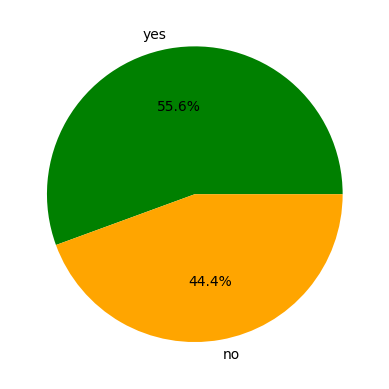

In [14]:
p = df["housing"]
counts = p.value_counts()

plt.pie(
    counts,
    labels=counts.index,
    colors=["green","Orange"],
    autopct="%1.1f%%"
)
plt.show()

## Original age outlier filtering

### Inspecting age with a boxplot
The box shows the middle 50% of ages, and the central line is the median. Points beyond the whiskers are flagged by the IQR rule.

### Applying the IQR rule
This preserves your original decision to filter age. Later sections clearly state whether they use the original `df` or the age-filtered `final_df`.

Text(0.5, 0, 'Age (years)')

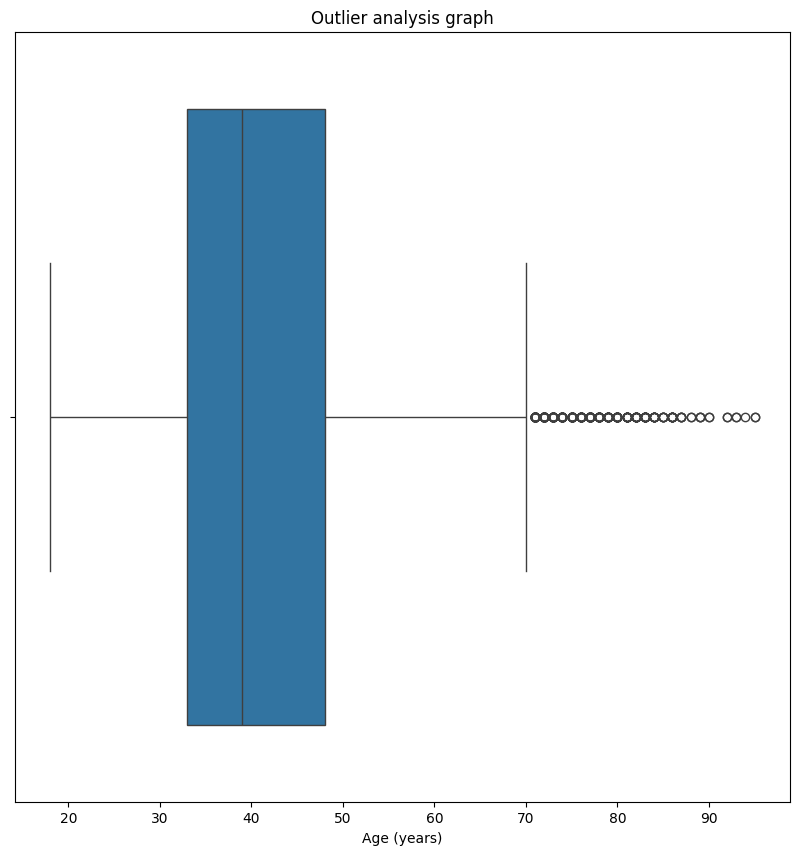

In [15]:
age=df['age']
plt.figure(figsize=(10,10))
sns.boxplot(x=age)
plt.title("Outlier analysis graph")
plt.xlabel("Age (years)")

### Before filtering
The previous plot displays the original age distribution.

### How the IQR calculation works

1. Find $Q_1$ (25th percentile) and $Q_3$ (75th percentile).
2. Calculate $IQR = Q_3-Q_1$.
3. Calculate the lower fence: $Q_1-1.5\times IQR$.
4. Calculate the upper fence: $Q_3+1.5\times IQR$.
5. Keep rows whose age falls between the fences.

**Correction:** values outside the box ($Q_1$ to $Q_3$) are not automatically outliers. The usual boxplot rule flags values outside the **fences**. Also, a flagged observation can be a valid customer; age filtering is a sensitivity choice, not proof of incorrect data.

In [16]:
age.describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [17]:
q1=df['age'].quantile(0.25)
q3=df['age'].quantile(0.75)
iqr=q3-q1
lower_limit=q1-1.5*iqr
upper_limit=q3+1.5*iqr
final_df = df[df["age"].between(lower_limit, upper_limit)]

In [18]:
final_df.shape[0]

44724

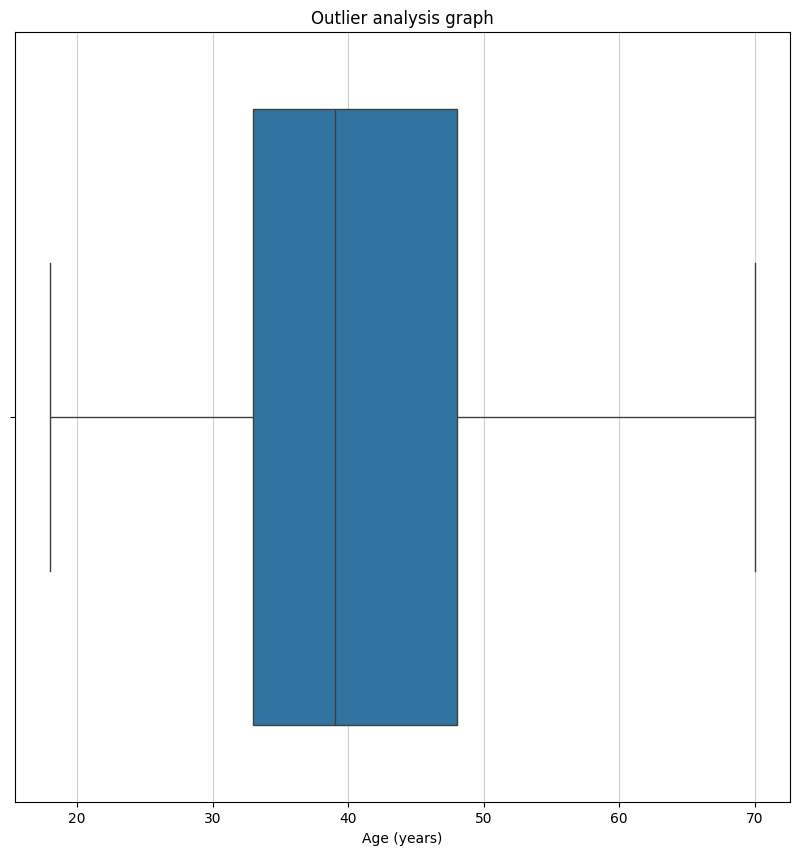

In [19]:
plt.figure(figsize=(10,10))
sns.boxplot(x=final_df['age'])
plt.title("Outlier analysis graph")
plt.xlabel("Age (years)")
plt.grid(axis="x", alpha=0.6)

### After filtering
The fences are **10.5 to 70.5 years**. There are **44,724 rows** remaining, with ages 18–70. The rule removes 487 older customers. Recomputing a boxplot on the filtered data can change its quartiles, so this is a one-time filter rather than repeated removal until every point disappears.

## Original feature-correlation inspection

### Correlation matrix

`corr(numeric_only=True)` computes Pearson correlations for numeric columns. The target `y` is text and is **excluded**. `.abs()` removes the sign, so this original matrix shows strength only.

The correct formula is:

$$r_{XY}=\frac{\operatorname{cov}(X,Y)}{s_Xs_Y}.$$

The value ranges from $-1$ to $+1$. A value near zero means a weak **linear** association; it does not rule out nonlinear dependence or associations with categorical variables. A threshold such as 0.7 is a descriptive convention, not a requirement for continuing EDA.

In [20]:
cor=final_df.corr(numeric_only=True).abs()
cor

,age,balance,day,duration,campaign,pdays,previous
age,1.000000,0.086714,0.007038,0.016227,0.012869,0.032578,0.009489
balance,0.086714,1.000000,0.005294,0.019215,0.013328,0.000453,0.013611
day,0.007038,0.005294,1.000000,0.029863,0.163304,0.094075,0.052174
duration,0.016227,0.019215,0.029863,1.000000,0.084458,0.002952,0.000584
campaign,0.012869,0.013328,0.163304,0.084458,1.000000,0.088486,0.032455
pdays,0.032578,0.000453,0.094075,0.002952,0.088486,1.000000,0.454488
previous,0.009489,0.013611,0.052174,0.000584,0.032455,0.454488,1.000000


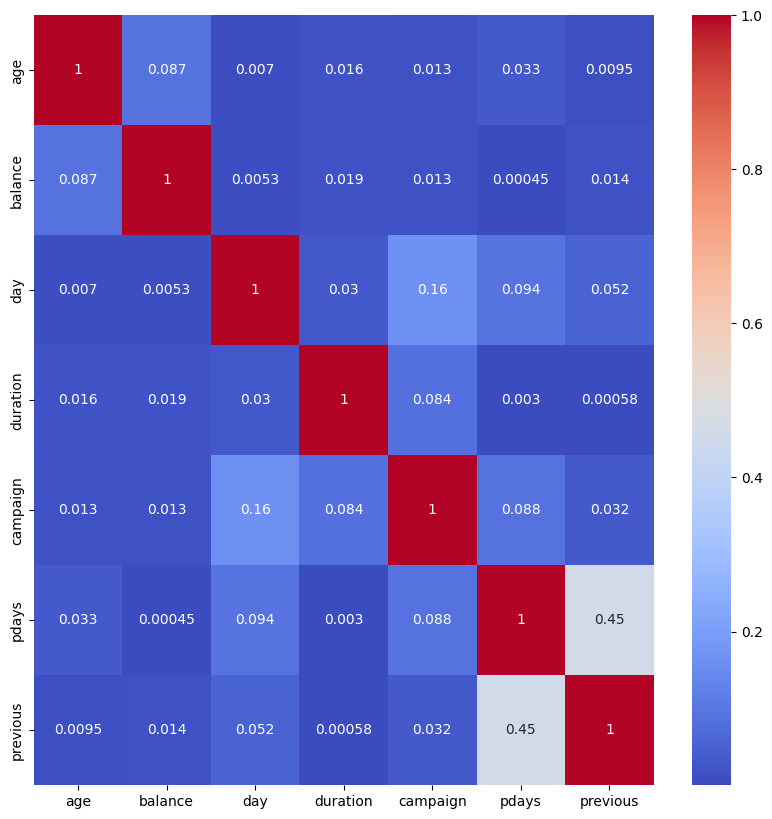

In [21]:
plt.figure(figsize=(10,10))
sns.heatmap(cor, annot=True, cmap="coolwarm")
plt.show()

### Why we can continue
The original numeric heatmap has no off-diagonal correlation above 0.7, but `pdays` and `previous` have a moderate positive relationship. More importantly, the target `y` and categorical predictors were omitted. Part C uses a signed heatmap and **SelectKBest with mutual information** to examine relationships with `y` directly. PCA and clustering can also proceed without a strongly correlated predictor pair.

# Part B — Complete assignment Sections 1 and 2
## 1. Data loading and cleaning

### 1.1 What are the variables and their data types?
The original file has **16 predictor columns plus the outcome `y`**. One observation is one recorded bank-marketing record. `int64` means an integer and `object` stores the text categories here. A numeric storage type does not always imply a continuous measurement: `day` is a calendar day and the contact counts are discrete.

The table below provides each column's meaning, stored type and number of distinct values. These meanings follow the Bank Marketing field conventions; the data file itself contains no separate data dictionary.

In [22]:
import numpy as np
from IPython.display import display

meaning = {
    'age': 'Customer age in years',
    'job': 'Job category',
    'marital': 'Marital status',
    'education': 'Education category',
    'default': 'Has credit in default: yes/no',
    'balance': 'Average yearly account balance (dataset convention: euros)',
    'housing': 'Has a housing loan: yes/no',
    'loan': 'Has a personal loan: yes/no',
    'contact': 'Contact communication type',
    'day': 'Day of month of last contact',
    'month': 'Month of last contact',
    'duration': 'Last contact duration in seconds',
    'campaign': 'Number of contacts during this campaign',
    'pdays': 'Days since previous campaign contact; -1 means no previous contact',
    'previous': 'Number of contacts before this campaign',
    'poutcome': 'Outcome of previous marketing campaign',
    'y': 'Subscribed to a term deposit: yes/no (target)'
}

variable_details = pd.DataFrame({
    'Data type': df.dtypes.astype(str),
    'Distinct values': df.nunique(),
    'Meaning': pd.Series(meaning)
})
display(variable_details)
print('Observations:', df.shape[0])
print('Variables:', df.shape[1])

,Data type,Distinct values,Meaning
age,int64,77,Customer age in years
job,object,12,Job category
marital,object,3,Marital status
education,object,4,Education category
default,object,2,Has credit in default: yes/no
balance,int64,7168,Average yearly account balance (dataset conven...
housing,object,2,Has a housing loan: yes/no
loan,object,2,Has a personal loan: yes/no
contact,object,3,Contact communication type
day,int64,31,Day of month of last contact


Observations: 45211
Variables: 17


### 1.2 Missing-value counts, proportions and treatment
NaN counts alone miss text placeholders. We separately count `unknown`, retain it as an explicit category, and do not replace it with the most common value, which would pretend that information is known. In particular, an unknown previous-campaign outcome may accompany no previous contact.

`pdays = -1` is a special code, not a negative number of elapsed days. We preserve it in the original analysis and exclude it when plotting elapsed days against previous contacts. Its use in PCA is explained later.

If actual numeric values were missing, median imputation would be a reasonable starting choice for skewed columns; if a future predictive model is built, fit imputers on training data only.

In [23]:
missing_table = pd.DataFrame({
    'NaN count': df.isna().sum(),
    'NaN percent': df.isna().mean() * 100,
    'Unknown count': df.eq('unknown').sum(),
    'Unknown percent': df.eq('unknown').mean() * 100
})
display(missing_table.round(2))
print('Duplicate rows:', df.duplicated().sum())
print('No previous contact (pdays = -1):', (df['pdays'] == -1).sum())

,NaN count,NaN percent,Unknown count,Unknown percent
age,0,0.0,0,0.00
job,0,0.0,288,0.64
marital,0,0.0,0,0.00
education,0,0.0,1857,4.11
default,0,0.0,0,0.00
balance,0,0.0,0,0.00
housing,0,0.0,0,0.00
loan,0,0.0,0,0.00
contact,0,0.0,13020,28.80
day,0,0.0,0,0.00


Duplicate rows: 0
No previous contact (pdays = -1): 36954


**Interpretation:** there are no NaNs or duplicate rows. `unknown` occurs in job, education, contact and previous outcome; the table quantifies the proportions. Previous outcome has the most unknown values, so discarding every row containing `unknown` would lose a large fraction of the data.

### 1.3 How does the original age filter affect the data?
This comparison reports the subscription rate before and after filtering. All remaining analysis uses `final_df` unless explicitly labelled otherwise. The filtered results describe the retained population, so conclusions should not automatically be extended to customers above 70.

In [24]:
filter_comparison = pd.DataFrame({
    'Rows': [len(df), len(final_df)],
    'Subscription percent': [df['y'].eq('yes').mean() * 100,
                             final_df['y'].eq('yes').mean() * 100]
}, index=['Original df', 'Age-filtered final_df'])
display(filter_comparison.round(2))
print('Rows removed:', len(df) - len(final_df))
print('Percent removed:', round((len(df) - len(final_df)) / len(df) * 100, 2))

,Rows,Subscription percent
Original df,45211,11.70
Age-filtered final_df,44724,11.34


Rows removed: 487
Percent removed: 1.08


**Interpretation:** removing 487 rows (about 1.08%) changes the yes rate from about **11.70% to 11.34%**. Even a small filter can alter the outcome mix. Retaining all valid ages would also be a defensible EDA choice; we keep your filter to continue your program consistently.

## 2. Univariate data description
### 2.1 Descriptive statistics for every numeric variable
`select_dtypes()` selects columns by stored type. `describe().T` displays one row per variable. We add the median, first mode and skewness. If several values tie for mode, the first is shown. Positive skewness indicates a longer right tail.

In [25]:
numeric_columns = final_df.select_dtypes(include='number').columns
category_columns = final_df.select_dtypes(include='object').columns

statistics = final_df[numeric_columns].describe().T
statistics['median'] = final_df[numeric_columns].median()
statistics['first_mode'] = final_df[numeric_columns].mode().iloc[0]
statistics['skewness'] = final_df[numeric_columns].skew()
display(statistics.round(2))

,count,mean,std,min,25%,50%,75%,max,median,first_mode,skewness
age,44724.0,40.55,9.98,18.0,33.0,39.0,48.0,70.0,39.0,32,0.42
balance,44724.0,1345.34,2983.22,-8019.0,71.0,442.0,1408.0,102127.0,442.0,0,8.01
day,44724.0,15.81,8.32,1.0,8.0,16.0,21.0,31.0,16.0,20,0.09
duration,44724.0,257.37,257.43,0.0,103.0,179.0,318.0,4918.0,179.0,124,3.16
campaign,44724.0,2.77,3.11,1.0,1.0,2.0,3.0,63.0,2.0,1,4.89
pdays,44724.0,40.00,100.19,-1.0,-1.0,-1.0,-1.0,871.0,-1.0,-1,2.63
previous,44724.0,0.57,2.30,0.0,0.0,0.0,0.0,275.0,0.0,0,42.40


**Interpretation:** age has a mean around 40.55 and a median of 39 after filtering. Balance has a mean around 1,345.34 and a median of 442, suggesting a long upper tail. Duration averages about 257 seconds, compared with a median of 179. Campaign and previous-contact counts also have long right tails. The median `pdays` of -1 represents no previous contact, not a typical elapsed time.

### 2.2 Frequency tables for all categorical variables
For every category, show its count and share of the filtered dataset. This includes the target, so we can assess outcome imbalance.

In [26]:
for column in category_columns:
    frequency = final_df[column].value_counts().to_frame('Count')
    frequency['Percent'] = frequency['Count'] / len(final_df) * 100
    print('Column:', column)
    display(frequency.round(2))

Column: job


,Count,Percent
job,,
blue-collar,9729,21.75
management,9445,21.12
technician,7594,16.98
admin.,5168,11.56
services,4154,9.29
retired,1830,4.09
self-employed,1573,3.52
entrepreneur,1485,3.32
unemployed,1303,2.91


Column: marital


,Count,Percent
marital,,
married,26848,60.03
single,12778,28.57
divorced,5098,11.40


Column: education


,Count,Percent
education,,
secondary,23070,51.58
tertiary,13214,29.55
primary,6634,14.83
unknown,1806,4.04


... (10 outputs left out)

Column: poutcome


,Count,Percent
poutcome,,
unknown,36653,81.95
failure,4836,10.81
other,1805,4.04
success,1430,3.20


Column: y


,Count,Percent
y,,
no,39653,88.66
yes,5071,11.34


**Interpretation:** the next compact table identifies the most frequent category in each column. `y = no` is much more common than `yes`, so future model evaluation should account for imbalance. A frequent `unknown` value represents missing information rather than a known customer characteristic.

In [27]:
most_frequent = pd.DataFrame({
    'Most frequent category': final_df[category_columns].mode().iloc[0],
    'Count': [final_df[column].value_counts().iloc[0] for column in category_columns]
})
most_frequent['Percent'] = most_frequent['Count'] / len(final_df) * 100
display(most_frequent.round(2))

,Most frequent category,Count,Percent
job,blue-collar,9729,21.75
marital,married,26848,60.03
education,secondary,23070,51.58
default,no,43910,98.18
housing,yes,25118,56.16
loan,no,37483,83.81
contact,cellular,29021,64.89
month,may,13746,30.74
poutcome,unknown,36653,81.95
y,no,39653,88.66


### 2.3 Histograms and boxplots for every numeric variable
Each row below contains a histogram and boxplot of the same column. The histogram shows shape and the boxplot highlights extreme values. The loop repeats the same simple plotting code for all seven numeric columns.

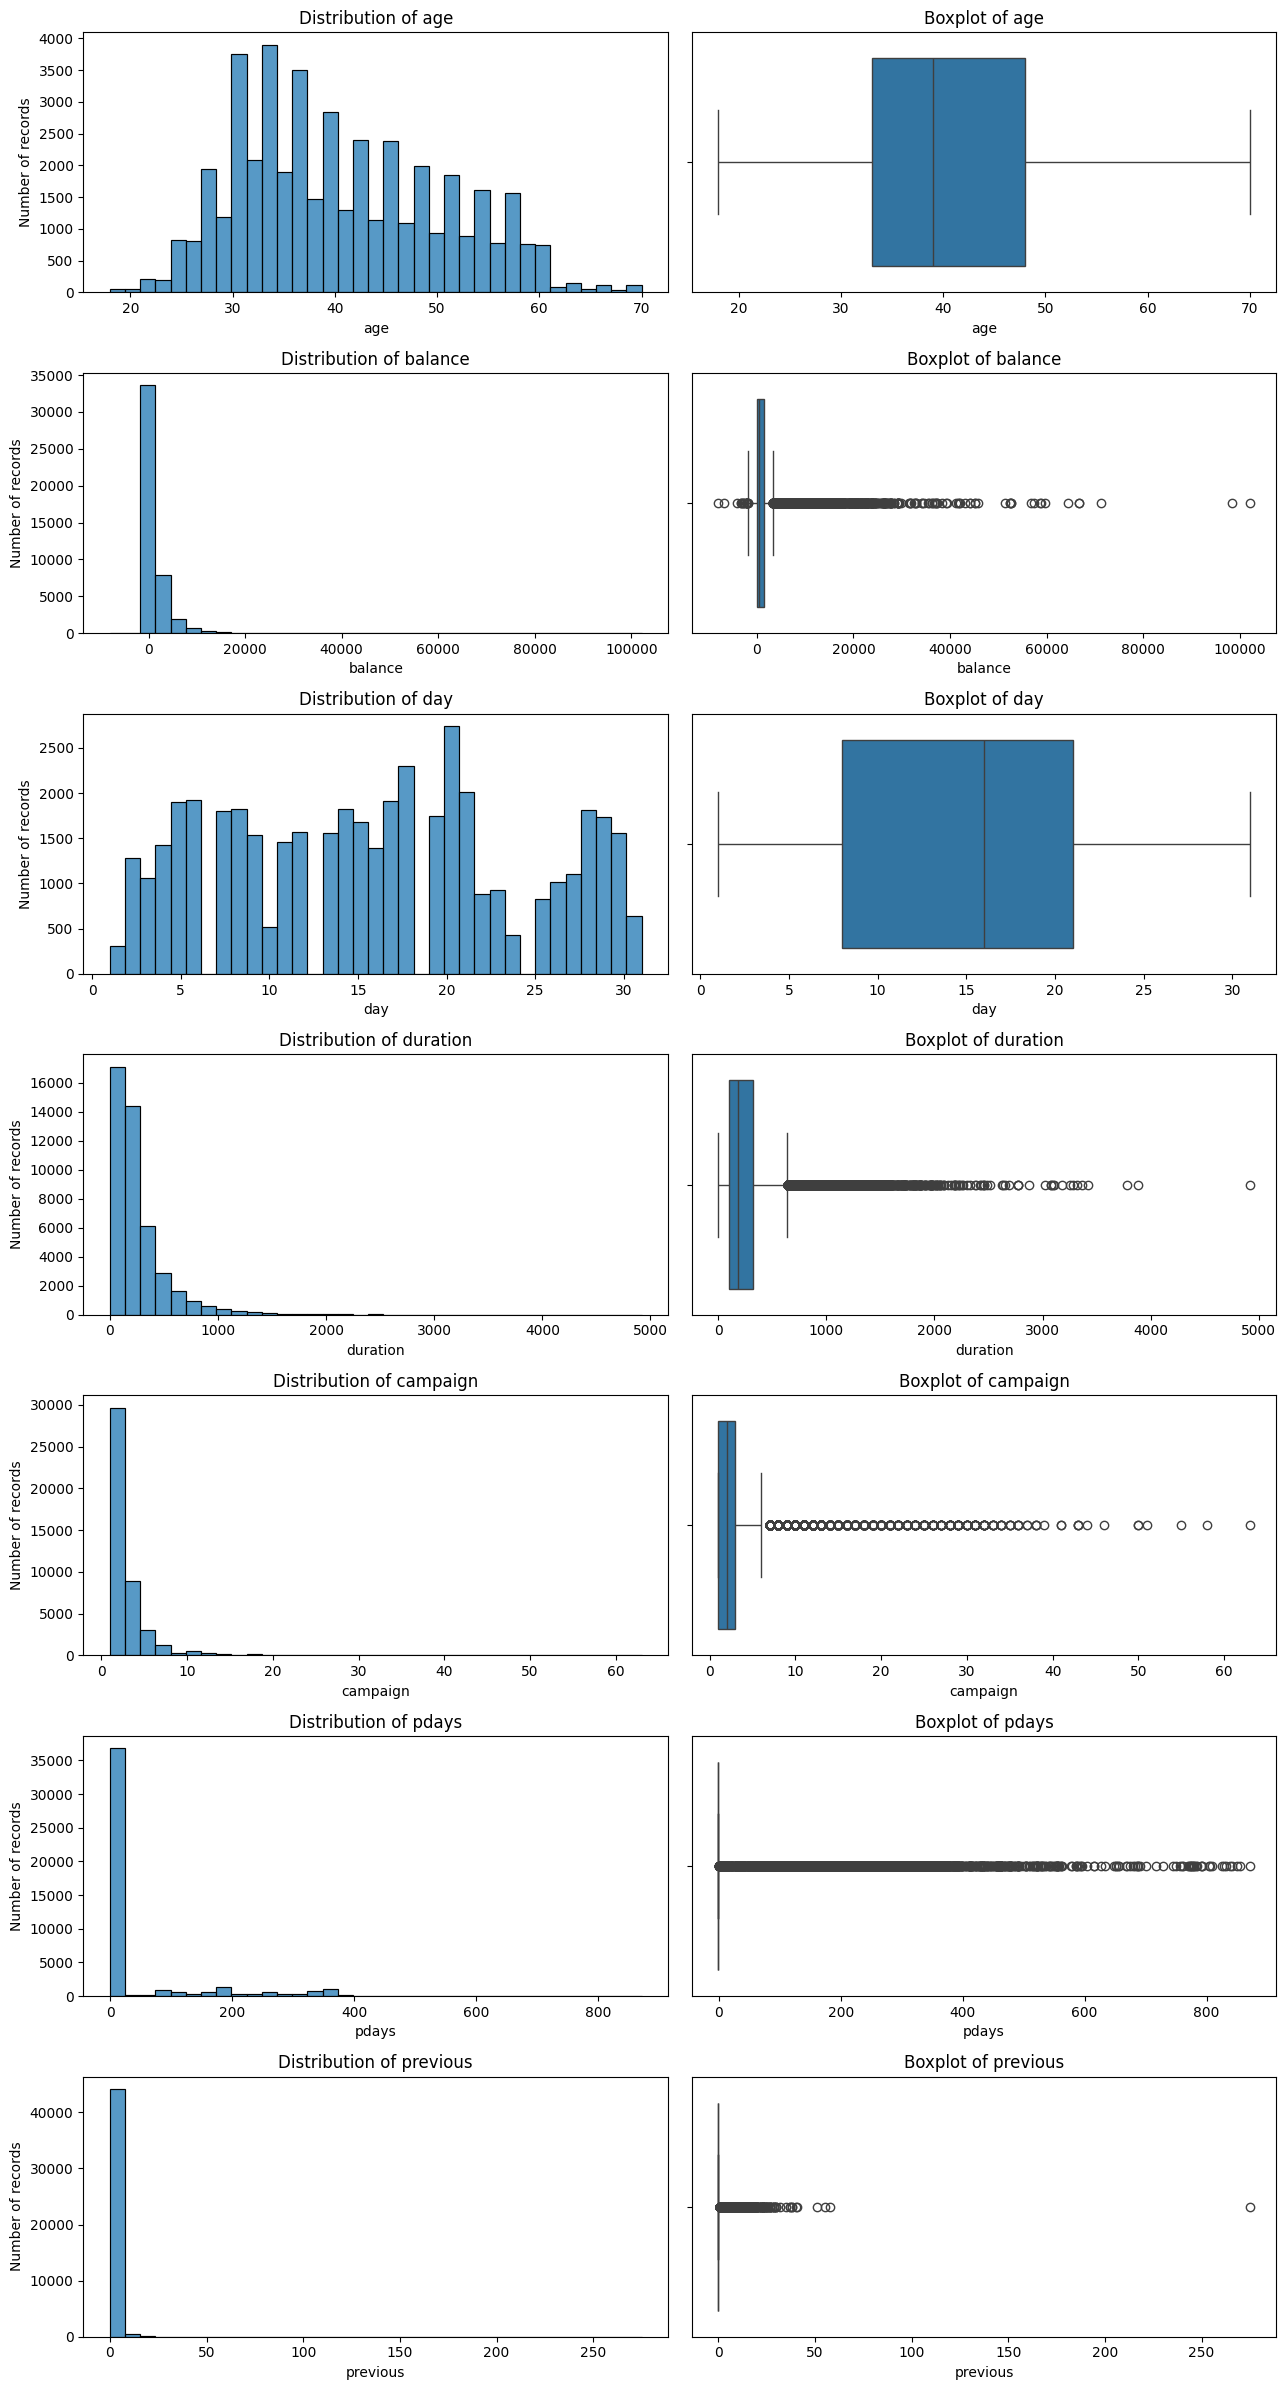

In [28]:
fig, axes = plt.subplots(len(numeric_columns), 2, figsize=(13, 24))
for i, column in enumerate(numeric_columns):
    sns.histplot(data=final_df, x=column, bins=35, ax=axes[i, 0])
    axes[i, 0].set_title('Distribution of ' + column)
    axes[i, 0].set_ylabel('Number of records')
    sns.boxplot(data=final_df, x=column, ax=axes[i, 1])
    axes[i, 1].set_title('Boxplot of ' + column)
plt.tight_layout()
plt.show()

**Interpretation:** balance, duration, campaign, pdays and previous are right-skewed. Balance includes negative values, which are possible account balances and are not automatically errors. Day is much less skewed than the financial and contact variables; age is mildly right-skewed after filtering. The spike at -1 in pdays reflects records with no previous contact. Large previous-contact counts, including the maximum of 275, deserve investigation, but are retained because there is no evidence here that they are erroneous.

### 2.4 Bar charts for categorical variables
Bars are sorted by frequency. Axis labels give the column name and record count; rotated category labels keep longer names readable. The original housing pie chart already provides an additional categorical display.

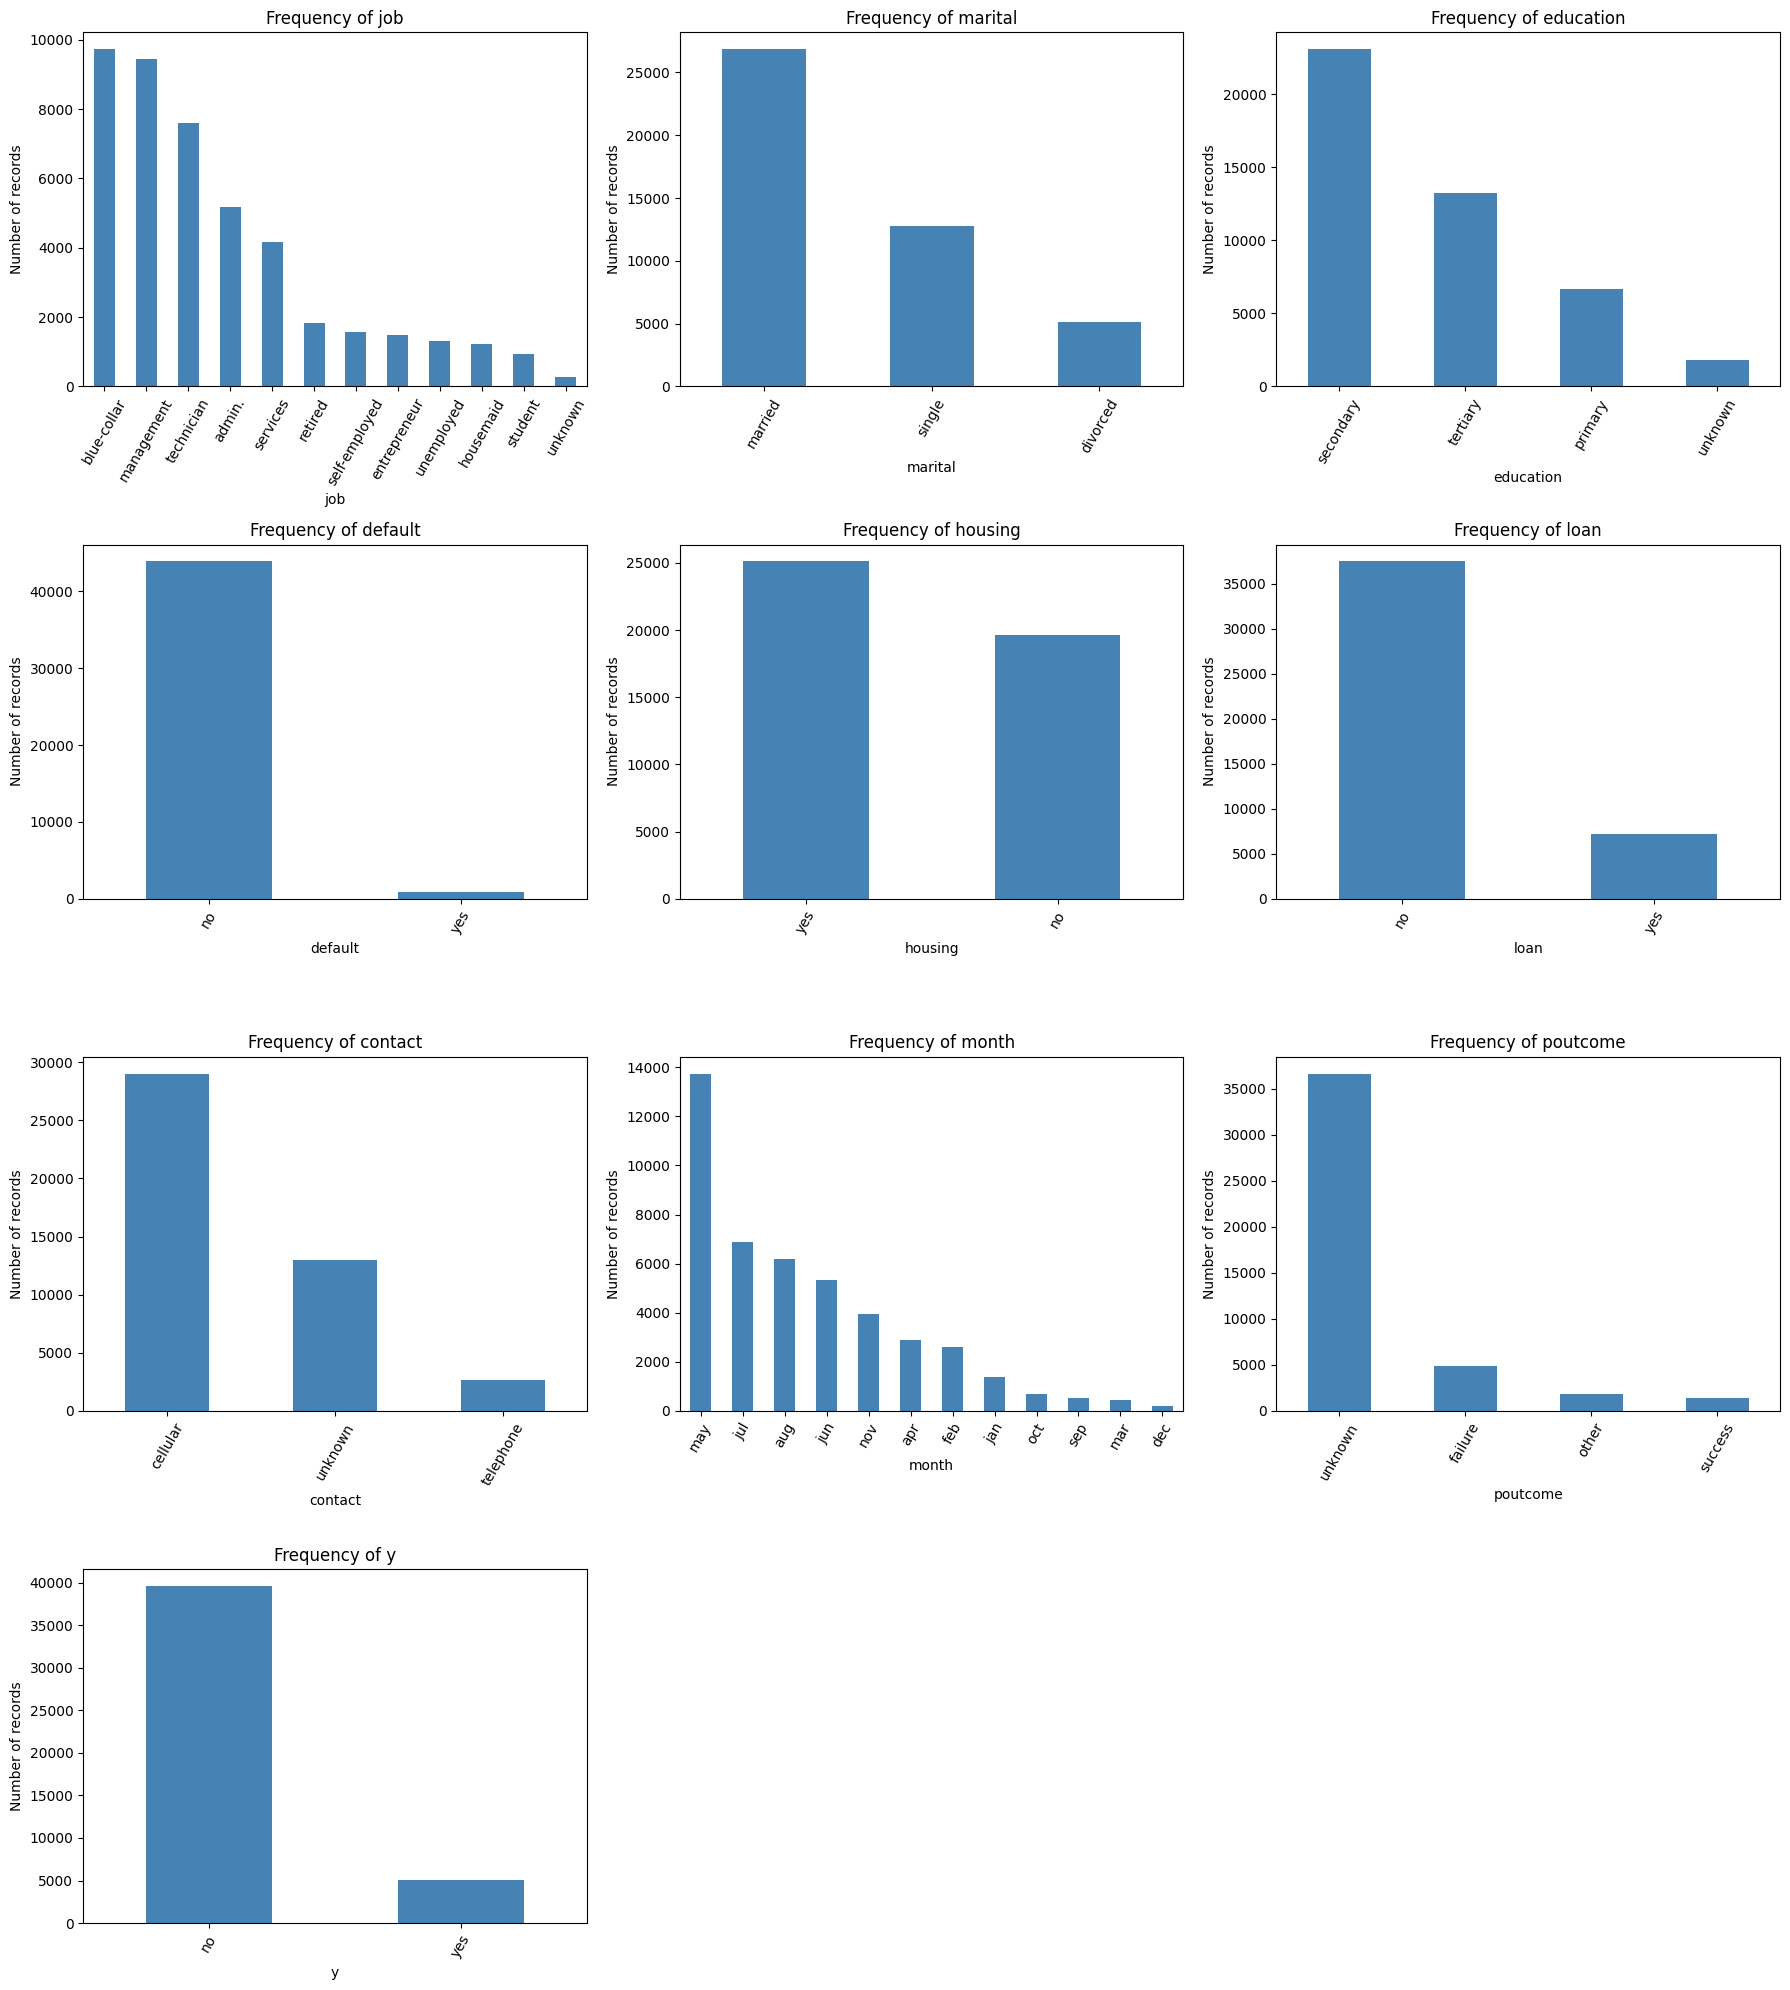

In [29]:
fig, axes = plt.subplots(4, 3, figsize=(18, 20))
for i, column in enumerate(category_columns):
    counts = final_df[column].value_counts()
    counts.plot(kind='bar', ax=axes.flat[i], color='steelblue')
    axes.flat[i].set_title('Frequency of ' + column)
    axes.flat[i].set_xlabel(column)
    axes.flat[i].set_ylabel('Number of records')
    axes.flat[i].tick_params(axis='x', labelrotation=60)
for i in range(len(category_columns), 12):
    axes.flat[i].set_visible(False)
plt.tight_layout()
plt.show()

**Interpretation:** the tallest bar in each chart is the most frequent category listed in the preceding table. The target bars show the strong no/yes imbalance. These charts describe category frequency, not the probability of subscription within each category; that comparison comes next.

# Part C — Assignment Section 3 and SelectKBest
## 3. Bivariate and multivariate description
### 3.1 Signed correlations among numeric variables
We keep the sign this time. Red/positive means variables tend to increase together; blue/negative means one tends to decrease as the other increases. The diagonal is always 1 because a variable is perfectly correlated with itself.

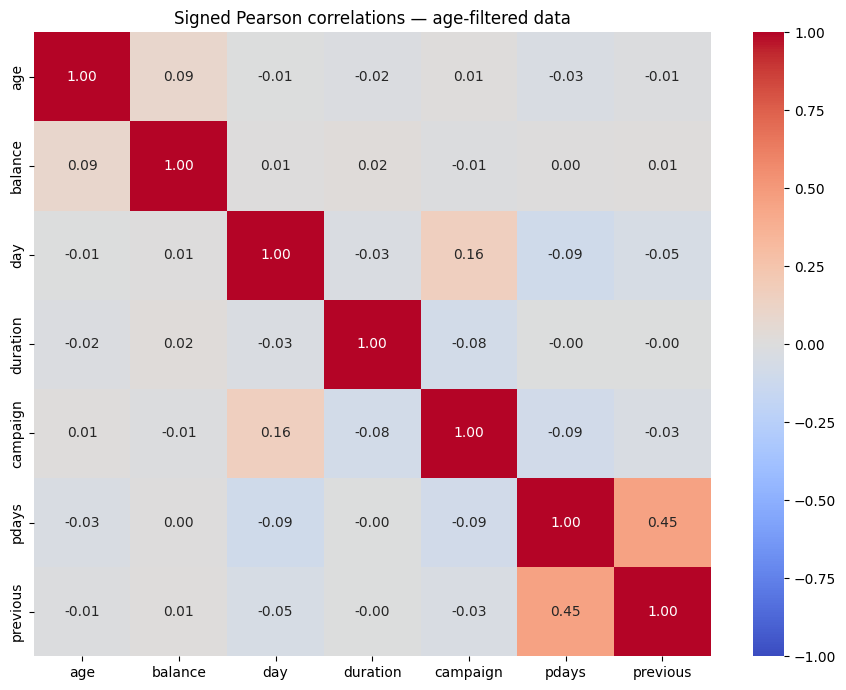

In [30]:
signed_cor = final_df[numeric_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(signed_cor, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-1, vmax=1, center=0)
plt.title('Signed Pearson correlations — age-filtered data')
plt.tight_layout()
plt.show()

**Interpretation:** the strongest numeric pair is `pdays` and `previous`, around **+0.45**. Campaign and day have a weaker positive correlation, around +0.16. Most other linear relationships are weak. The pdays sentinel and the concentration at zero previous contacts affect this matrix, so a scatterplot restricted to previously contacted customers is useful.

### 3.2 SelectKBest: choose predictors for the target `y`

**Target (`y`):** whether a customer subscribed to a term deposit. This is a classification outcome, encoded as no = 0 and yes = 1. We choose the target from the meaning of the assignment dataset; a selector does not discover the target for us.

**Predictors (`X`):** all columns except `y`. `pd.get_dummies()` turns each category into a separate 0/1 column, avoiding an artificial order such as management > technician. An encoded feature such as `poutcome_success` means the customer has that previous-campaign outcome.

We use `SelectKBest` from `sklearn.feature_selection`, with **mutual information** as its scoring method. Mutual information can detect nonlinear as well as linear dependence. We tell it which columns are discrete, including one-hot features and integer counts. Balance and duration are treated as measured quantities. A fixed random seed makes the estimation repeatable.

**Why k = 8?** This is a small, readable exploratory subset, not a proven optimal number. `fit_transform(X, y)` scores each encoded predictor against the target and retains the eight highest-scoring features. A larger score indicates more estimated dependence; it is not a correlation coefficient, percentage accuracy or proof of causation. This is a univariate ranking and can miss interactions between features.

This selection uses the full filtered dataset for **descriptive EDA only**. If later training a classifier, split first and fit selection only on training data (and within each cross-validation fold).

In [31]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from functools import partial

X = pd.get_dummies(final_df.drop(columns='y'), dtype=int)
y = final_df['y'].map({'no': 0, 'yes': 1})

discrete_features = ~X.columns.isin(['balance', 'duration'])
mi_score = partial(mutual_info_classif,
                   discrete_features=discrete_features,
                   random_state=42)
selector = SelectKBest(score_func=mi_score, k=8)
X_selected = selector.fit_transform(X, y)

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'MI score': selector.scores_,
    'Selected': selector.get_support()
}).sort_values('MI score', ascending=False)
selected_columns = X.columns[selector.get_support()]
X_selected = pd.DataFrame(X_selected, columns=selected_columns,
                          index=final_df.index)

display(feature_scores.head(20).round(4))
print('Selected features:', list(selected_columns))
print('Selected data shape:', X_selected.shape)
display(X_selected.head())

ModuleNotFoundError: No module named 'sklearn'

### Reading the feature-selection results
The table marks the eight retained encoded columns, and the chart below compares their scores. A category can contribute several encoded columns; eight selected features do not necessarily mean eight different original variables.

**Duration caution:** duration is known only after the call ends. It is meaningful for retrospective EDA, but must be excluded from a model intended to decide whom to contact before a call. No predictive performance is claimed in this notebook.

**Observed selection:** in descending score order, the eight selected encoded predictors are **duration, pdays, poutcome_success, balance, contact_unknown, previous, poutcome_unknown and contact_cellular**. Duration has the largest estimated mutual information (about 0.0721 nats). The selection spans call duration, account balance and contact/campaign history. Both `contact_unknown` and `contact_cellular` describe the same original variable, so some selected information is redundant. The score ranking is exploratory and depends on the estimator and data treatment.


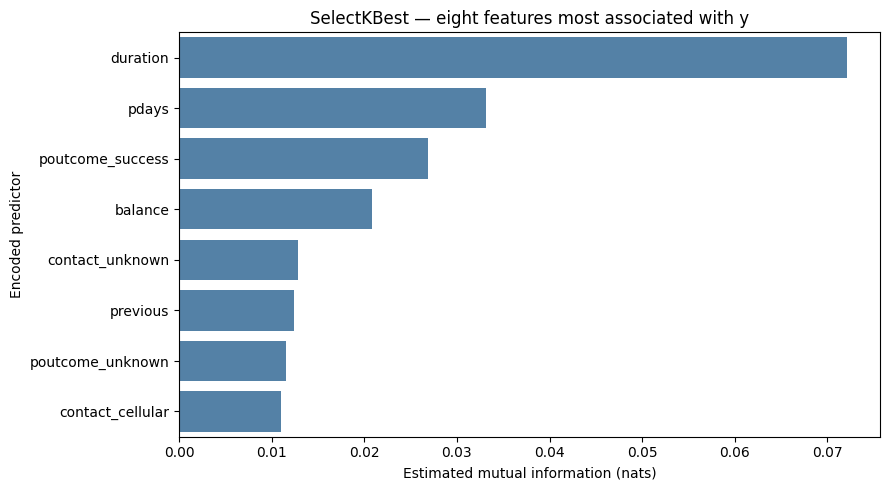

In [ ]:
selected_scores = feature_scores[feature_scores['Selected']]
plt.figure(figsize=(9, 5))
sns.barplot(data=selected_scores, x='MI score', y='Feature', color='steelblue')
plt.title('SelectKBest — eight features most associated with y')
plt.xlabel('Estimated mutual information (nats)')
plt.ylabel('Encoded predictor')
plt.tight_layout()
plt.show()

### 3.3 Scatterplots for pairs of numeric variables
A scatterplot does not need a correlation above 0.7. We examine two numeric pairs and use colour to display the target. A reproducible sample of up to 3,000 rows limits overplotting; tables and feature selection use all filtered rows.

The first plot uses previously contacted customers only, so -1 is not interpreted as elapsed days. The second examines balance and duration. Any apparent pattern is an association, not evidence that changing one variable causes the other to change.

pdays/previous correlation among previously contacted customers: -0.02


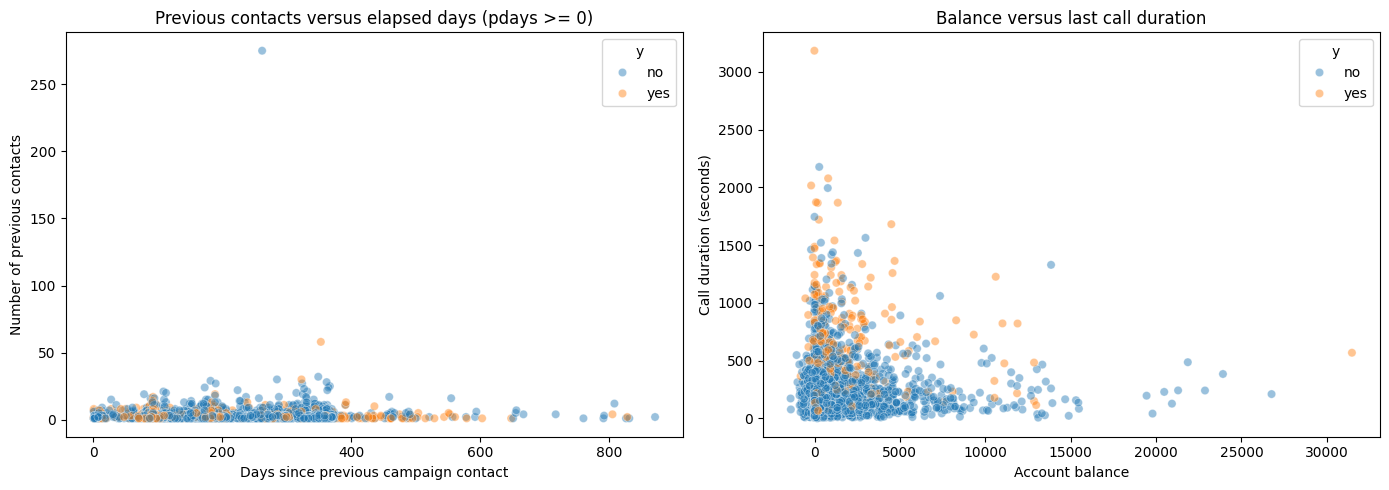

In [ ]:
previously_contacted = final_df[final_df['pdays'] >= 0]
plot_previous = previously_contacted.sample(n=min(3000, len(previously_contacted)),
                                          random_state=42)
plot_sample = final_df.sample(n=min(3000, len(final_df)), random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=plot_previous, x='pdays', y='previous', hue='y',
                hue_order=['no', 'yes'], alpha=0.45, ax=axes[0])
axes[0].set_title('Previous contacts versus elapsed days (pdays >= 0)')
axes[0].set_xlabel('Days since previous campaign contact')
axes[0].set_ylabel('Number of previous contacts')
sns.scatterplot(data=plot_sample, x='balance', y='duration', hue='y',
                hue_order=['no', 'yes'], alpha=0.45, ax=axes[1])
axes[1].set_title('Balance versus last call duration')
axes[1].set_xlabel('Account balance')
axes[1].set_ylabel('Call duration (seconds)')
plt.tight_layout()
plt.show()
print('pdays/previous correlation among previously contacted customers:',
      round(previously_contacted['pdays'].corr(previously_contacted['previous']), 3))

**Interpretation:** the points do not form a tight straight line. The contacted-only correlation printed above shows how much the overall pdays/previous relationship depends on mixing previously contacted and never-contacted records. Balance and duration have little linear association. Dense bands and extreme observations are visible; these displays do not establish a clear nonlinear functional relationship either.

### 3.4 Compare a numeric variable across categories
We compare **duration across subscription outcomes** because duration is a numeric feature considered by SelectKBest. The boxplot uses all filtered rows; extreme points are hidden in this display only (`showfliers=False`). They are still included in the summaries and all computations.

,count,mean,median,std,min,max
y,,,,,,
no,39653,220.84,164.0,207.12,0,4918
yes,5071,543.05,434.0,396.22,8,3881


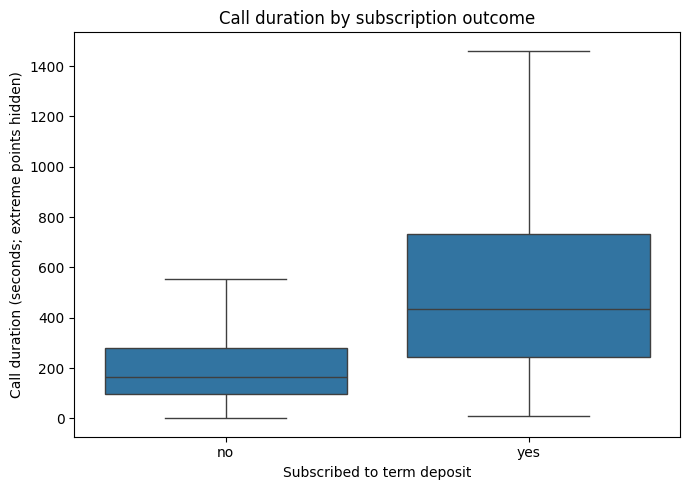

In [ ]:
duration_summary = final_df.groupby('y')['duration'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max'])
display(duration_summary.round(2))

plt.figure(figsize=(7, 5))
sns.boxplot(data=final_df, x='y', y='duration', order=['no', 'yes'],
            showfliers=False)
plt.title('Call duration by subscription outcome')
plt.xlabel('Subscribed to term deposit')
plt.ylabel('Call duration (seconds; extreme points hidden)')
plt.tight_layout()
plt.show()

**Interpretation:** yes records have a median duration of **434 seconds**, versus **164 seconds** for no records. Their means are about 543 and 221 seconds. The distributions overlap, so duration alone does not determine the outcome. Its timing also prevents it from being used as a pre-call predictor.

### 3.5 Contingency table for categorical variables
`pd.crosstab()` counts each combination of previous campaign outcome and the current subscription outcome. Row percentages answer: within each previous-outcome category, what proportion subscribed? This corrects for unequal category sizes.

Counts:
Row percentages:


y,no,yes
poutcome,,
failure,4243,593
other,1508,297
success,510,920
unknown,33392,3261


y,no,yes
poutcome,,
failure,87.74,12.26
other,83.55,16.45
success,35.66,64.34
unknown,91.10,8.90


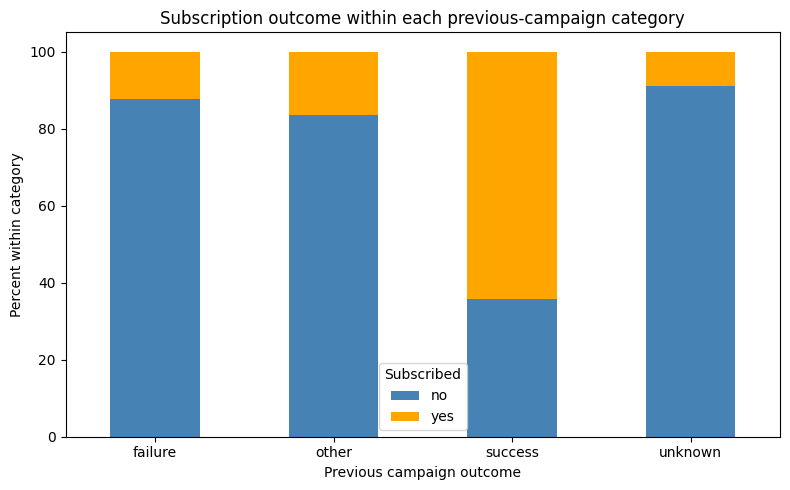

In [ ]:
contingency = pd.crosstab(final_df['poutcome'], final_df['y'])
row_percent = pd.crosstab(final_df['poutcome'], final_df['y'],
                         normalize='index') * 100
print('Counts:')
display(contingency)
print('Row percentages:')
display(row_percent.round(2))

row_percent[['no', 'yes']].plot(kind='bar', stacked=True, figsize=(8, 5),
                               color=['steelblue', 'orange'])
plt.title('Subscription outcome within each previous-campaign category')
plt.xlabel('Previous campaign outcome')
plt.ylabel('Percent within category')
plt.legend(title='Subscribed')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Interpretation:** records with a successful previous campaign have a yes rate around **64.34%**, compared with about **8.90%** for unknown previous outcomes. This is an association within this dataset. It does not imply that a previous success causes a new subscription, and unknown is not equivalent to a previous failure.

# Part D — Assignment Section 4
## 4. Principal Component Analysis and clustering
### 4.1 Encode, scale and apply PCA

PCA finds new axes that summarise variation among predictors. **PC1** captures the most variance; **PC2** captures the most remaining variance while being perpendicular to PC1. PCA is unsupervised: it does not use the target.

SelectKBest answered which features are associated with `y`. For the assignment's unsupervised PCA and clustering, we use **all encoded predictors in X**, rather than the target-selected subset. This avoids making the groups depend on the subscription labels by design. The target is excluded, and `X_selected` remains available for a future supervised task.

`StandardScaler()` centres every encoded column and scales it to unit standard deviation. This prevents large numerical units, such as balance, from automatically dominating. We then fit PCA and keep enough components for at least **80%** of the variance. The unit of variance is the chosen, standardised encoded feature space, not the original categorical variables.

**Choices and limits:** all one-hot levels are retained for transparent category interpretation. Their redundancy is acceptable to PCA, but standardising each dummy gives rare categories substantial influence and gives multi-level variables several columns. `pdays = -1` remains a sentinel in this simple baseline, not a literal time. Duration remains because this is retrospective EDA. These choices affect distances and should be revisited before using clusters operationally.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(svd_solver='full')
pca_values = pca.fit_transform(X_scaled)
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)
n_components_80 = np.argmax(cumulative_variance >= 0.80) + 1

variance_table = pd.DataFrame({
    'Component': np.arange(1, len(cumulative_variance) + 1),
    'Variance percent': pca.explained_variance_ratio_ * 100,
    'Cumulative percent': cumulative_variance * 100
})
display(variance_table.round(2))
print('Encoded predictor columns:', X.shape[1])
print('Components needed for at least 80%:', n_components_80)
print('Variance retained:', round(cumulative_variance[n_components_80 - 1] * 100, 2), '%')

pca_df = pd.DataFrame(pca_values[:, :2], columns=['PC1', 'PC2'],
                      index=final_df.index)
X_pca_80 = pca_values[:, :n_components_80]

Encoded predictor columns: 51
Components needed for at least 80%: 27
Variance retained: 80.03 %


,Component,Variance percent,Cumulative percent
0,1,7.34,7.34
1,2,6.48,13.82
2,3,4.81,18.63
3,4,4.67,23.30
4,5,4.12,27.42
5,6,3.83,31.25
6,7,3.46,34.71
7,8,3.08,37.79
8,9,2.83,40.62
9,10,2.72,43.35


### 4.2 How many components explain at least 80%?
The table gives the exact answer. The dashed horizontal line is the assignment's 80% threshold; the vertical line marks the first component count that reaches it. The first two PCs are useful for display, but may capture much less than 80%. Clustering below therefore uses **all retained 80%-variance PCs**, not only the two plotted axes.

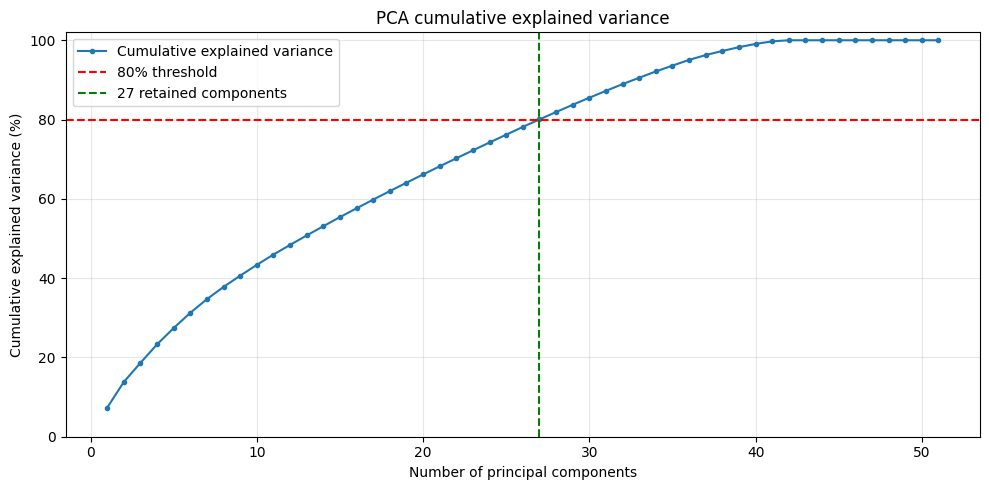

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(variance_table['Component'], variance_table['Cumulative percent'],
         marker='o', markersize=3, label='Cumulative explained variance')
plt.axhline(80, color='red', linestyle='--', label='80% threshold')
plt.axvline(n_components_80, color='green', linestyle='--',
            label=str(n_components_80) + ' retained components')
plt.title('PCA cumulative explained variance')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance (%)')
plt.ylim(0, 102)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.3 Loading vectors: correlation circle
A correlation circle places each predictor at its correlations with PC1 and PC2. Coordinates are computed directly using Pearson correlation, so they remain on the correlation scale.

- Arrows pointing in similar directions indicate similar associations with the displayed PCs.
- Opposite arrows indicate contrasting associations on those axes.
- Longer arrows indicate better representation in this two-PC plane; a short arrow can still matter on later PCs.

There are many encoded columns, so the circle labels the **12 best represented** in this plane. The table retains all coordinates. Full one-hot coding means opposite dummy arrows can simply reflect mutually exclusive categories. These arrows describe encoded features, not causal effects.

,PC1 correlation,PC2 correlation,Plane representation
poutcome_unknown,0.805,-0.420,0.825
pdays,-0.720,0.475,0.745
contact_unknown,0.692,0.320,0.582
housing_no,-0.161,-0.744,0.579
housing_yes,0.161,0.744,0.579
contact_cellular,-0.666,-0.280,0.522
poutcome_failure,-0.592,0.385,0.499
month_may,0.281,0.597,0.435
previous,-0.524,0.280,0.353
month_aug,-0.112,-0.480,0.243


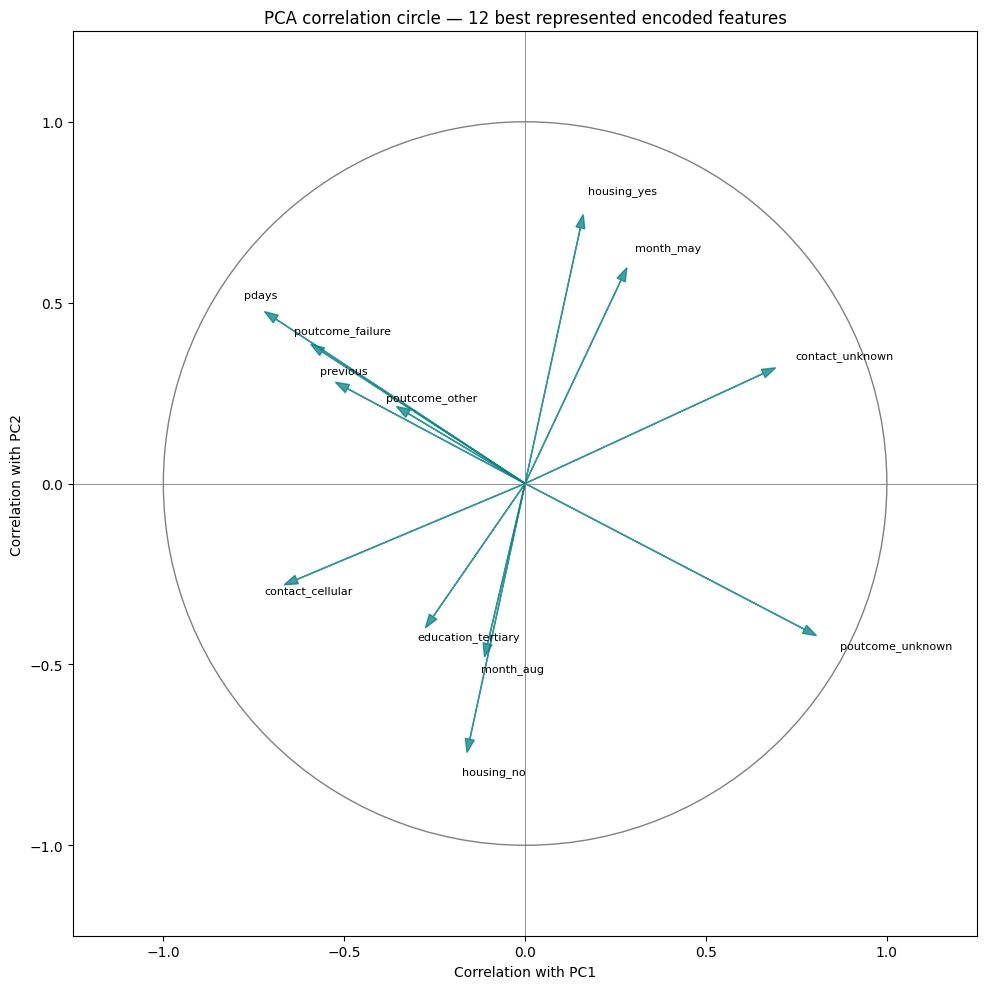

In [ ]:
scaled_df = pd.DataFrame(X_scaled, columns=X.columns, index=X.index)
loadings = pd.DataFrame({
    'PC1 correlation': scaled_df.corrwith(pca_df['PC1']),
    'PC2 correlation': scaled_df.corrwith(pca_df['PC2'])
})
loadings['Plane representation'] = (loadings['PC1 correlation'] ** 2 +
                                     loadings['PC2 correlation'] ** 2)
loadings = loadings.sort_values('Plane representation', ascending=False)
display(loadings.round(3))
top_loadings = loadings.head(12)

fig, ax = plt.subplots(figsize=(10, 10))
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color='grey'))
for feature, row in top_loadings.iterrows():
    x = row['PC1 correlation']
    z = row['PC2 correlation']
    ax.arrow(0, 0, x, z, color='teal', alpha=0.75,
             head_width=0.025, length_includes_head=True)
    ax.text(x * 1.08, z * 1.08, feature, fontsize=8)
ax.axhline(0, color='grey', linewidth=0.6)
ax.axvline(0, color='grey', linewidth=0.6)
ax.set_xlim(-1.25, 1.25)
ax.set_ylim(-1.25, 1.25)
ax.set_aspect('equal')
ax.set_xlabel('Correlation with PC1')
ax.set_ylabel('Correlation with PC2')
ax.set_title('PCA correlation circle — 12 best represented encoded features')
plt.tight_layout()
plt.show()

### 4.4 What do PC1 and PC2 represent?
We sort by absolute correlation on each axis and inspect the strongest contributors. The sign of a PCA axis can flip between software implementations; relative directions and explained variance stay equivalent. Component names must follow the observed loadings rather than being assumed to mean subscription success.

In [ ]:
pc1_features = loadings['PC1 correlation'].abs().nlargest(6).index
pc2_features = loadings['PC2 correlation'].abs().nlargest(6).index
print('Features most strongly associated with PC1:')
display(loadings.loc[pc1_features, ['PC1 correlation']].round(3))
print('Features most strongly associated with PC2:')
display(loadings.loc[pc2_features, ['PC2 correlation']].round(3))
print('Variance in PC1 and PC2 together:',
      round(pca.explained_variance_ratio_[:2].sum() * 100, 2), '%')

Features most strongly associated with PC1:
Features most strongly associated with PC2:
Variance in PC1 and PC2 together: 13.82 %


,PC1 correlation
poutcome_unknown,0.805
pdays,-0.720
contact_unknown,0.692
contact_cellular,-0.666
poutcome_failure,-0.592
previous,-0.524


,PC2 correlation
housing_no,-0.744
housing_yes,0.744
month_may,0.597
month_aug,-0.480
pdays,0.475
poutcome_unknown,-0.420


### 4.5 Biplot: observations and feature directions together
The points are up to 2,000 sampled records, coloured by their known subscription outcome **only for interpretation**. The target was not used to fit PCA. The six strongest arrows from the correlation circle are shown for readability.

The point coordinates below are actual PC scores. Arrow coordinates are feature–PC correlations multiplied by 3 to make them visible in score units. Thus arrow lengths and point distances have different scales; the separate correlation circle is the correct display for reading correlation magnitudes.

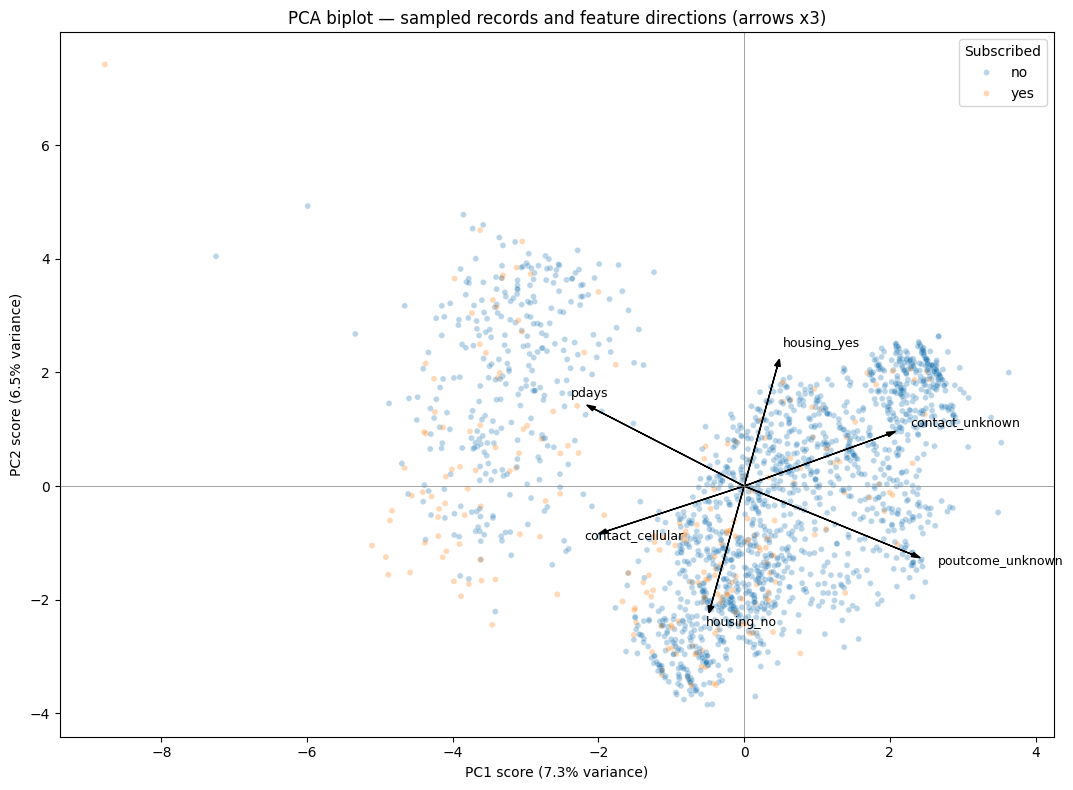

In [ ]:
biplot_sample = pca_df.sample(n=min(2000, len(pca_df)), random_state=42).copy()
biplot_sample['y'] = final_df.loc[biplot_sample.index, 'y']

plt.figure(figsize=(11, 8))
sns.scatterplot(data=biplot_sample, x='PC1', y='PC2', hue='y',
                hue_order=['no', 'yes'], alpha=0.3, s=18)
for feature, row in top_loadings.head(6).iterrows():
    x = row['PC1 correlation'] * 3
    z = row['PC2 correlation'] * 3
    plt.arrow(0, 0, x, z, color='black', head_width=0.08,
              length_includes_head=True)
    plt.text(x * 1.1, z * 1.1, feature, fontsize=9)
plt.axhline(0, color='grey', linewidth=0.5)
plt.axvline(0, color='grey', linewidth=0.5)
plt.title('PCA biplot — sampled records and feature directions (arrows x3)')
plt.xlabel('PC1 score (' + str(round(pca.explained_variance_ratio_[0] * 100, 1)) + '% variance)')
plt.ylabel('PC2 score (' + str(round(pca.explained_variance_ratio_[1] * 100, 1)) + '% variance)')
plt.legend(title='Subscribed')
plt.tight_layout()
plt.show()

**Interpretation:** read groups in the point cloud alongside the loading directions. Overlap between no and yes records means these two unsupervised axes do not cleanly separate subscription outcomes. Because this is only a two-dimensional projection, apparent overlap does not by itself prove that the higher-dimensional clusters overlap equally.

### 4.6 Choose a clustering algorithm and a number of clusters
We use **KMeans** as a simple baseline. It assigns records to the nearest centroid and favours compact groups under Euclidean distance. `n_init=10` tries ten starting configurations per candidate and `random_state=42` makes the run repeatable.

We test **k = 2 to 8** in the retained PCA space. Inertia decreases as k grows, so an elbow can be informative but subjective. Our explicit selection rule is the **highest sampled silhouette score** among these candidates. Silhouette ranges from -1 to 1: higher values indicate better separation, values near zero indicate overlap, and negative values suggest some points are closer to another group.

Each KMeans model is fitted on all filtered rows. Silhouette is computed using the same reproducible sample of up to **2,000** rows to avoid the expense of all pairwise distances. Therefore the chosen k is the best tested value under this preprocessing and approximate score, not a guaranteed natural or globally optimal cluster count.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca_80)
    score = silhouette_score(X_pca_80, labels,
                             sample_size=2000, random_state=42)
    cluster_results.append([k, model.inertia_, score])

cluster_results = pd.DataFrame(cluster_results,
                                columns=['k', 'Inertia', 'Silhouette'])
display(cluster_results.round(4))
best_k = int(cluster_results.loc[cluster_results['Silhouette'].idxmax(), 'k'])
print('Chosen cluster count:', best_k)

Chosen cluster count: 2


,k,Inertia,Silhouette
0,2,1.681033e+06,0.1716
1,3,1.571768e+06,0.0810
2,4,1.510381e+06,0.0834
3,5,1.432521e+06,0.0854
4,6,1.382738e+06,0.0863
5,7,1.340333e+06,0.0788
6,8,1.312697e+06,0.0801


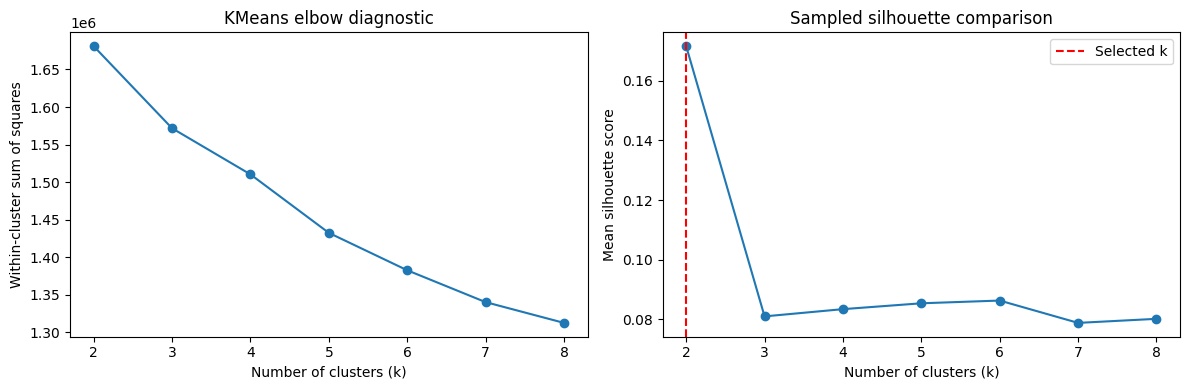

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(cluster_results['k'], cluster_results['Inertia'], marker='o')
axes[0].set_title('KMeans elbow diagnostic')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('Within-cluster sum of squares')
axes[1].plot(cluster_results['k'], cluster_results['Silhouette'], marker='o')
axes[1].axvline(best_k, color='red', linestyle='--', label='Selected k')
axes[1].set_title('Sampled silhouette comparison')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Mean silhouette score')
axes[1].legend()
plt.tight_layout()
plt.show()

### 4.7 Visualise the resulting clusters
We fit the chosen KMeans model in the retained PCA space and display cluster labels on PC1/PC2. Crosses show the first two coordinates of the fitted centroids. Up to 4,000 records are displayed, while all records receive a cluster assignment. Cluster numbers are arbitrary identifiers, not ordered quality ratings.

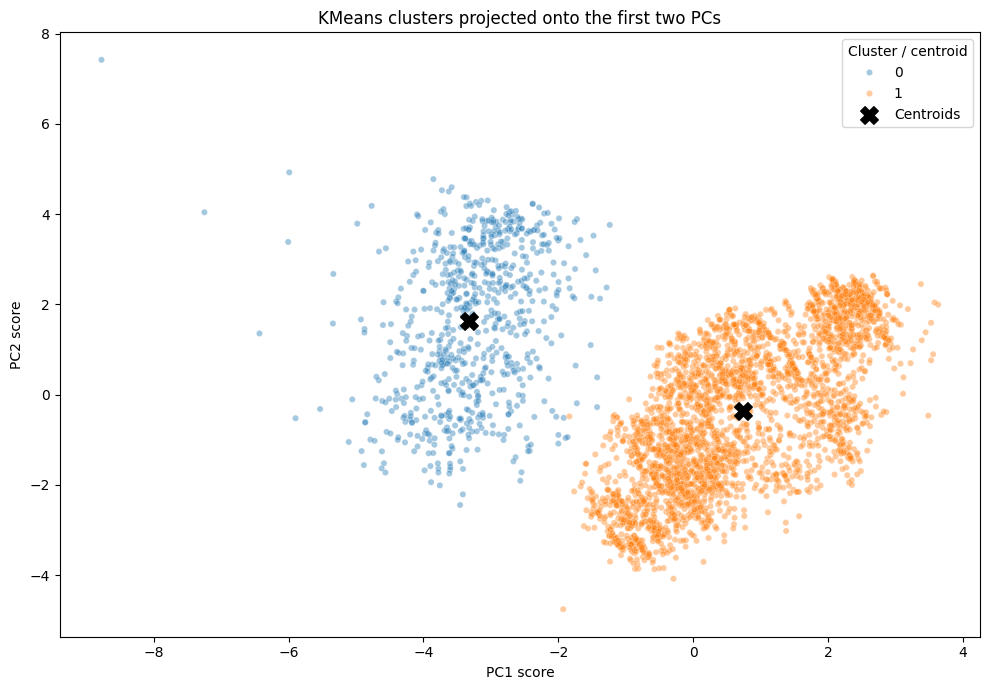

In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_pca_80)
cluster_plot = pca_df.copy()
cluster_plot['Cluster'] = cluster_labels.astype(str)
cluster_sample = cluster_plot.sample(n=min(4000, len(cluster_plot)), random_state=42)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=cluster_sample, x='PC1', y='PC2', hue='Cluster',
                palette='tab10', alpha=0.4, s=20)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            color='black', marker='X', s=160, label='Centroids')
plt.title('KMeans clusters projected onto the first two PCs')
plt.xlabel('PC1 score')
plt.ylabel('PC2 score')
plt.legend(title='Cluster / centroid')
plt.tight_layout()
plt.show()

### 4.8 Are the clusters well separated? What characterises them?
Use the sampled silhouette score to assess separation in the space used for clustering, and use the plot to describe only the two-PC projection. The next summaries describe cluster sizes, numeric medians, common categories and outcome rates.

`y` is added **after** clustering for interpretation, never as an input. Cluster yes rates are descriptive and are not held-out prediction results. Median summaries reduce the influence of highly skewed numeric values.

In [ ]:
clustered_df = final_df.copy()
clustered_df['Cluster'] = cluster_labels
clustered_df['Subscribed'] = y

cluster_summary = clustered_df.groupby('Cluster').agg(
    Records=('y', 'size'),
    Subscription_rate=('Subscribed', 'mean')
)
cluster_summary['Share percent'] = cluster_summary['Records'] / len(clustered_df) * 100
cluster_summary['Subscription percent'] = cluster_summary.pop('Subscription_rate') * 100
display(cluster_summary.round(2))
print('Numeric medians by cluster:')
display(clustered_df.groupby('Cluster')[list(numeric_columns)].median().round(2))
print('Most common categorical value in each cluster:')
display(clustered_df.groupby('Cluster')[['job', 'marital', 'education',
                                         'contact', 'poutcome']].agg(
                                             lambda column: column.mode().iloc[0]))
chosen_silhouette = cluster_results.loc[cluster_results['k'] == best_k,
                                       'Silhouette'].iloc[0]
print('Selected sampled silhouette:', round(chosen_silhouette, 4))

Numeric medians by cluster:
Most common categorical value in each cluster:
Selected sampled silhouette: 0.1716


,Records,Share percent,Subscription percent
Cluster,,,
0,8074,18.05,22.42
1,36650,81.95,8.90


,age,balance,day,duration,campaign,pdays,previous
Cluster,,,,,,,
0,38.0,586.5,14.0,191.0,2.0,196.0,2.0
1,39.0,410.0,17.0,177.0,2.0,-1.0,0.0


,job,marital,education,contact,poutcome
Cluster,,,,,
0,management,married,secondary,cellular,failure
1,blue-collar,married,secondary,cellular,unknown


### Results from this run: PCA and clustering

**Variance:** **27 principal components** are needed to retain **80.03%** of the variance in the standardised encoded predictors. PC1 and PC2 together retain only **13.82%**, so a two-dimensional plot is a small part of the total structure.

**PC1 — previous-campaign and contact-information contrast:** the strongest positive associations are `poutcome_unknown` (+0.805) and `contact_unknown` (+0.692). The strongest negative associations include `pdays` (-0.720), `contact_cellular` (-0.666), `poutcome_failure` (-0.592) and `previous` (-0.524). Thus this axis mainly contrasts unknown/no-history records with records containing previous-contact information. Because -1 encodes no previous contact, part of this structure is driven by that sentinel.

**PC2 — housing-loan and campaign-month contrast:** `housing_yes` (+0.744) and `month_may` (+0.597) contrast with `housing_no` (-0.744) and `month_aug` (-0.480). It also has an association with pdays (+0.475). PC2 therefore mixes loan status, contact timing and history; it is not simply a measure of age, wealth or subscription likelihood.

**Observed grouping:** the biplot shows a left-hand group aligned with previous-contact/history variables and a broader right-hand cloud aligned with unknown history/contact categories. Housing and campaign month help describe the vertical contrast. Both subscription outcomes appear within these clouds, rather than forming two clean outcome groups.

**Chosen clustering:** **k = 2** has the highest silhouette among the tested values 2–8. Its sampled silhouette is **0.172**. This is a modest positive score: the groups have some separation, but the score does **not** support describing them as strongly separated in the full retained PCA space. The two-PC projection has a clearer visual gap than this overall score might suggest, illustrating why the plot alone is insufficient.

| Cluster | Records | Share | Subscription rate | Median pdays | Median previous contacts |
|---|---:|---:|---:|---:|---:|
| 0 | 8,074 | 18.05% | 22.42% | 196 | 2 |
| 1 | 36,650 | 81.95% | 8.90% | -1 (no previous contact) | 0 |

Cluster 0 has more previous-contact history and its most common previous outcome is failure. Cluster 1 is larger and its most common previous outcome is unknown. Their outcome rates differ, but y was not used to create them. These are exploratory segments under the chosen encoding and age filter, not established customer types or predictions.


# Part E — Assignment Section 5
## 5. Summary and interpretation

### 5.1 Main characteristics of the dataset
The original data contains **45,211 records and 17 variables**, including the binary subscription outcome. There are no NaNs or fully duplicated rows, but explicit unknown categories are common, particularly for previous campaign outcome. The original age filter retains **44,724 records** and changes the population by removing ages above 70.

The filtered outcome is imbalanced: approximately **88.66% no** and **11.34% yes**. Balance, duration and contact-related variables are strongly right-skewed, while age is less skewed after filtering. Means and medians therefore tell different stories for several variables.

### 5.2 Interesting patterns and differences
The numeric matrix contains mostly weak linear correlations, with a moderate association between pdays and previous. This is enough to investigate further; strong predictor-to-predictor correlation is not a prerequisite for EDA. SelectKBest provides a separate ranking of encoded predictors against the known classification target.

Subscription outcomes differ substantially across call-duration distributions and previous-campaign outcomes. Yes records have a longer median last-call duration (434 versus 164 seconds), and the previous-success category has a higher subscription share than unknown. These are observed associations, not causal findings.

PCA summarises the standardised encoded predictors, while KMeans groups records without using the target. The exact component count, dominant PC features and selected cluster count are stated in the result commentary above. The first two PCs are a limited visual summary, so the clustering uses the full set of components needed for at least 80% variance.

### 5.3 Anomalies, assumptions and next steps
- Extreme balances and previous-contact counts merit checking against the source, but are not deleted without evidence of error.
- `unknown` categories and `pdays = -1` need semantic treatment; neither is an ordinary NaN. A refined PCA could separate previous-contact status from valid elapsed days.
- Age filtering excludes valid older customers and changes the yes rate. A full-data sensitivity analysis would help assess this choice before operational use.
- Standardised one-hot features can give rare categories and variables with many levels substantial weight. Clusters should be checked under alternative encodings, scaling and random seeds before treating them as stable customer segments.
- SelectKBest ranks individual encoded features; its chosen k is illustrative and it does not test interactions or guarantee predictive usefulness.
- For a future pre-call classifier, remove duration, split the data before learned preprocessing, and fit transformations and feature selection on the training set only. No model accuracy or out-of-sample conclusion is claimed here.

### Assignment coverage checklist

| Assignment requirement | Location in this notebook |
|---|---|
| Load data, first rows, variable names/types and dimensions | Part A and Part B §1.1 |
| Missing counts, proportions and treatment | Part A and Part B §1.2 |
| Numeric summaries including mean, median, min, max and standard deviation | Part B §2.1 |
| Frequency tables for all categorical variables | Part B §2.2 |
| Histograms, boxplots and shape commentary for all numeric variables | Part B §2.3 |
| Categorical charts and most frequent categories | Part A pie chart and Part B §2.2–2.4 |
| Correlations and a heatmap | Part A and Part C §3.1 |
| Numeric scatterplots and relationship commentary | Part C §3.3 |
| Numeric distributions across categories | Part C §3.4 |
| Categorical contingency table | Part C §3.5 |
| Encode, scale and apply PCA; variance ≥80% | Part D §4.1–4.2 |
| Correlation circle, biplot and PC interpretation | Part D §4.3–4.5 and result commentary |
| Clustering algorithm, k selection, visualisation and separation | Part D §4.6–4.8 and result commentary |
| Summary, patterns, differences and anomalies | Part E §5.1–5.3 |
| Requested SelectKBest continuation | Part C §3.2 |

### Method references
Official scikit-learn documentation consulted for method behaviour:

- [Feature selection and mutual information](https://scikit-learn.org/stable/modules/feature_selection.html)
- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [Silhouette score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)

Dataset field definitions: [UCI Bank Marketing dataset](https://archive.ics.uci.edu/dataset/222/bank+marketing). The supplied file is the data used for all results; no external data is downloaded by the notebook.